Enter the path of the folder containing the .txt files:  /mnt/c/Users/bioed/OneDrive - Northwestern University/Desktop/tmavenMODS/GaussianFRET2/notRNA/


Area under Gaussian 1: 0.6278 ± 0.0102
Area under Gaussian 2: 0.2814 ± 0.0107
Ratio of Gaussian 2 area over total area: 0.3095 ± 0.0128


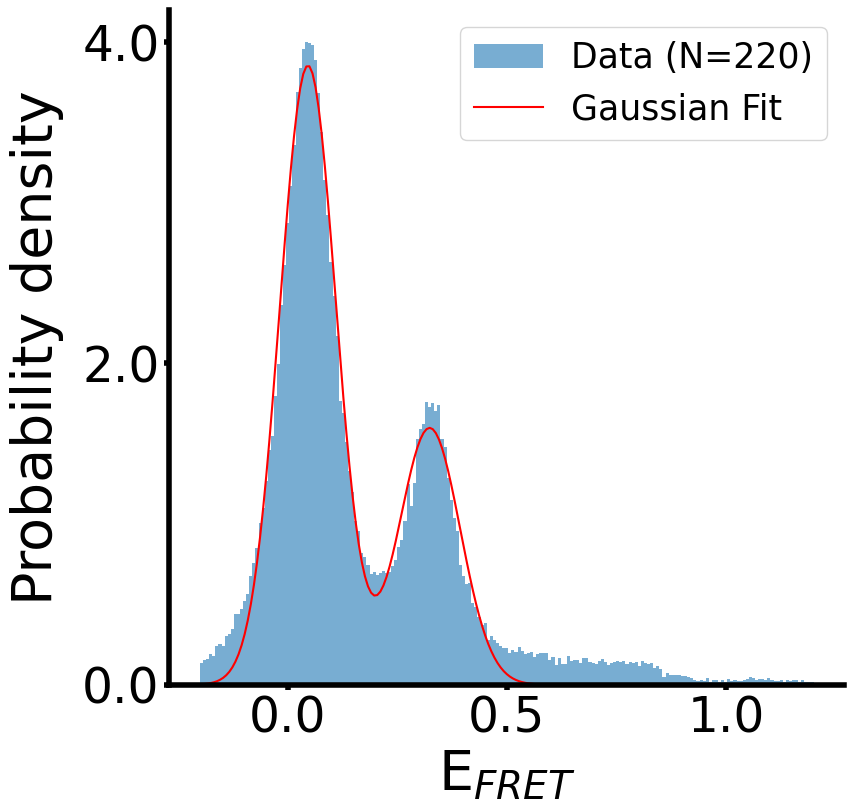

In [5]:
import os
import numpy as np
import csv
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from matplotlib.ticker import FormatStrFormatter

def read_data_from_file(file_path):
    """Read data from .txt file and compute efficiencies for the first 400 data points."""
    data = np.loadtxt(file_path, skiprows=1)
    num_cols = data.shape[1]
    
    # Consider only the first 400 data points
    data = data[:400, :]
    
    efficiencies = []
    for i in range(0, num_cols, 2):  # Process data in pairs of columns
        donor = data[:, i]
        acceptor = data[:, i + 1]
        efficiency = acceptor / (donor + acceptor)
        efficiencies.extend(efficiency)
    
    return efficiencies, num_cols

def save_efficiencies_to_csv(efficiencies, output_file_path):
    """Save the calculated FRET efficiencies to a CSV file."""
    with open(output_file_path, 'w', newline='') as file:
        writer = csv.writer(file)
        for efficiency in efficiencies:
            writer.writerow([efficiency])

def double_gaussian(x, amp1, cen1, sigma1, amp2, cen2, sigma2):
    """Model for a double Gaussian function."""
    return (amp1 * np.exp(-(x - cen1)**2 / (2 * sigma1**2)) +
            amp2 * np.exp(-(x - cen2)**2 / (2 * sigma2**2)))

def plot_histogram(efficiencies, num_observations, tick_count=3, label_fontsize=40, tick_fontsize=35, legend_fontsize=25, tick_decimals=1):
    """Plot histogram of FRET efficiencies and fit with double Gaussian."""
    bins = np.linspace(-0.2, 1.2, 200)
    hist_data, bin_edges = np.histogram(efficiencies, bins=bins, density=True)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
    
    # Fit the double Gaussian to the histogram data
    params, cov = curve_fit(double_gaussian, bin_centers, hist_data, 
                          p0=[max(hist_data)/2, 0, 0.1, max(hist_data)/2, 0.33, 0.1])

    std_errors = np.sqrt(np.diag(cov))
    
    # Calculate areas and their errors
    dx = bin_centers[1] - bin_centers[0]
    area1 = sum(params[0] * np.exp(-(bin_centers - params[1])**2 / (2 * params[2]**2)) * dx)
    area2 = sum(params[3] * np.exp(-(bin_centers - params[4])**2 / (2 * params[5]**2)) * dx)
    
    area1_error = np.sqrt((params[0] * np.sqrt(2*np.pi) * std_errors[2])**2 + (params[2] * np.sqrt(2*np.pi) * std_errors[0])**2)
    area2_error = np.sqrt((params[3] * np.sqrt(2*np.pi) * std_errors[5])**2 + (params[5] * np.sqrt(2*np.pi) * std_errors[3])**2)
    
    print(f"Area under Gaussian 1: {area1:.4f} ± {area1_error:.4f}")
    print(f"Area under Gaussian 2: {area2:.4f} ± {area2_error:.4f}")

    # After calculating areas and their errors
    total_area = area1 + area2
    total_area_error = np.sqrt(area1_error**2 + area2_error**2)

    ratio = area2 / total_area
    ratio_error = ratio * np.sqrt((area2_error/area2)**2 + (total_area_error/total_area)**2)

    print(f"Ratio of Gaussian 2 area over total area: {ratio:.4f} ± {ratio_error:.4f}")

    
    fig, ax = plt.subplots(figsize=(9, 9))  # Creating a square figure

    # Set the linewidth and tick parameters
    for _, spine in ax.spines.items():
        spine.set_linewidth(4.0)
    
    ax.tick_params(width=4.0, labelsize=tick_fontsize)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # Set ticks
    ax.set_xticks(np.linspace(0, 1, tick_count))  # This line ensures that x-ticks go from 0 to 1
    max_density = max(hist_data)
    ax.set_yticks(np.linspace(0, max_density, tick_count))

    # Format ticks to have the specified number of decimals
    ax.xaxis.set_major_formatter(FormatStrFormatter(f'%.{tick_decimals}f'))
    ax.yaxis.set_major_formatter(FormatStrFormatter(f'%.{tick_decimals}f'))
    
    # Plot the histogram and the fit
    ax.hist(efficiencies, bins=bins, density=True, alpha=0.6, edgecolor="none",
             label=f"Data (N={num_observations})")
    ax.plot(bin_centers, double_gaussian(bin_centers, *params), 'r-', label="Gaussian Fit")
    
    
    ax.set_xlabel(r"E$_{FRET}$", fontsize=label_fontsize)
    ax.set_ylabel("Probability density", fontsize=label_fontsize, labelpad=13)
    ax.legend(fontsize=legend_fontsize)
    
    fig.subplots_adjust(left=0.15, right=0.9, top=0.9, bottom=0.15)  # Adjust the subplot spacing to prevent squeezing
    #Save the plot as a .png file
    plt.savefig('notRNA.png', bbox_inches='tight', dpi=300)
    plt.show()

def main(folder_path):
    """Main function to process data from folder and plot histogram."""
    fret_efficiencies = []
    num_observations = 0

    for file_name in os.listdir(folder_path):
        if file_name.endswith('.txt'):
            file_path = os.path.join(folder_path, file_name)
            efficiencies, num_cols = read_data_from_file(file_path)
            fret_efficiencies.extend(efficiencies)
            num_observations += num_cols // 2  # since each observation is represented by a pair of columns

    plot_histogram(fret_efficiencies, num_observations)

    # Save the efficiencies to a CSV file
    output_file_path = os.path.join(folder_path, 'fret_efficiencies.csv')
    save_efficiencies_to_csv(fret_efficiencies, output_file_path)

if __name__ == "__main__":
    folder_path = input("Enter the path of the folder containing the .txt files: ")
    main(folder_path)

Enter the path of the folder containing the .txt files:  /mnt/c/Users/bioed/OneDrive - Northwestern University/Desktop/tmavenMODS/GaussianFRET2/NCCAtRNA/5uM/


Area under Gaussian 1: 0.5876 ± 0.0121
Area under Gaussian 2: 0.3338 ± 0.0159
Ratio of Gaussian 2 area over total area: 0.3623 ± 0.0189


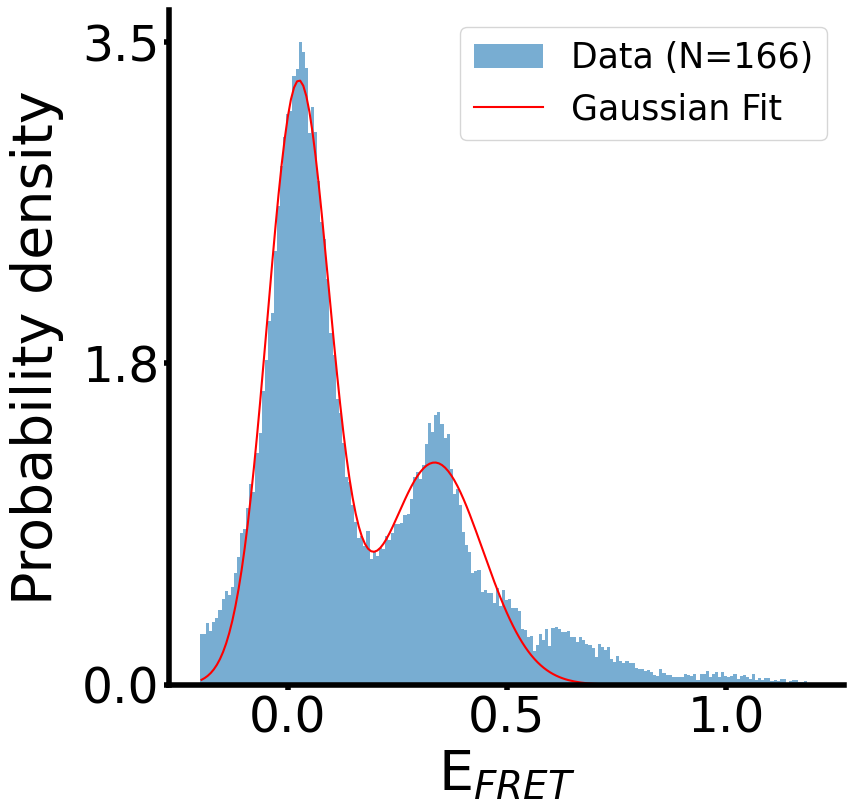

In [6]:
import os
import numpy as np
import csv
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from matplotlib.ticker import FormatStrFormatter

def read_data_from_file(file_path):
    """Read data from .txt file and compute efficiencies for the first 400 data points."""
    data = np.loadtxt(file_path, skiprows=1)
    num_cols = data.shape[1]
    
    # Consider only the first 400 data points
    data = data[:400, :]
    
    efficiencies = []
    for i in range(0, num_cols, 2):  # Process data in pairs of columns
        donor = data[:, i]
        acceptor = data[:, i + 1]
        efficiency = acceptor / (donor + acceptor)
        efficiencies.extend(efficiency)
    
    return efficiencies, num_cols

def save_efficiencies_to_csv(efficiencies, output_file_path):
    """Save the calculated FRET efficiencies to a CSV file."""
    with open(output_file_path, 'w', newline='') as file:
        writer = csv.writer(file)
        for efficiency in efficiencies:
            writer.writerow([efficiency])

def double_gaussian(x, amp1, cen1, sigma1, amp2, cen2, sigma2):
    """Model for a double Gaussian function."""
    return (amp1 * np.exp(-(x - cen1)**2 / (2 * sigma1**2)) +
            amp2 * np.exp(-(x - cen2)**2 / (2 * sigma2**2)))

def plot_histogram(efficiencies, num_observations, tick_count=3, label_fontsize=40, tick_fontsize=35, legend_fontsize=25, tick_decimals=1):
    """Plot histogram of FRET efficiencies and fit with double Gaussian."""
    bins = np.linspace(-0.2, 1.2, 200)
    hist_data, bin_edges = np.histogram(efficiencies, bins=bins, density=True)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
    
    # Fit the double Gaussian to the histogram data
    params, cov = curve_fit(double_gaussian, bin_centers, hist_data, 
                          p0=[max(hist_data)/2, 0, 0.1, max(hist_data)/2, 0.33, 0.1])

    std_errors = np.sqrt(np.diag(cov))
    
    # Calculate areas and their errors
    dx = bin_centers[1] - bin_centers[0]
    area1 = sum(params[0] * np.exp(-(bin_centers - params[1])**2 / (2 * params[2]**2)) * dx)
    area2 = sum(params[3] * np.exp(-(bin_centers - params[4])**2 / (2 * params[5]**2)) * dx)
    
    area1_error = np.sqrt((params[0] * np.sqrt(2*np.pi) * std_errors[2])**2 + (params[2] * np.sqrt(2*np.pi) * std_errors[0])**2)
    area2_error = np.sqrt((params[3] * np.sqrt(2*np.pi) * std_errors[5])**2 + (params[5] * np.sqrt(2*np.pi) * std_errors[3])**2)
    
    print(f"Area under Gaussian 1: {area1:.4f} ± {area1_error:.4f}")
    print(f"Area under Gaussian 2: {area2:.4f} ± {area2_error:.4f}")

    # After calculating areas and their errors
    total_area = area1 + area2
    total_area_error = np.sqrt(area1_error**2 + area2_error**2)

    ratio = area2 / total_area
    ratio_error = ratio * np.sqrt((area2_error/area2)**2 + (total_area_error/total_area)**2)

    print(f"Ratio of Gaussian 2 area over total area: {ratio:.4f} ± {ratio_error:.4f}")

    
    fig, ax = plt.subplots(figsize=(9, 9))  # Creating a square figure

    # Set the linewidth and tick parameters
    for _, spine in ax.spines.items():
        spine.set_linewidth(4.0)
    
    ax.tick_params(width=4.0, labelsize=tick_fontsize)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # Set ticks
    ax.set_xticks(np.linspace(0, 1, tick_count))  # This line ensures that x-ticks go from 0 to 1
    max_density = max(hist_data)
    ax.set_yticks(np.linspace(0, max_density, tick_count))

    # Format ticks to have the specified number of decimals
    ax.xaxis.set_major_formatter(FormatStrFormatter(f'%.{tick_decimals}f'))
    ax.yaxis.set_major_formatter(FormatStrFormatter(f'%.{tick_decimals}f'))
    
    # Plot the histogram and the fit
    ax.hist(efficiencies, bins=bins, density=True, alpha=0.6, edgecolor="none",
             label=f"Data (N={num_observations})")
    ax.plot(bin_centers, double_gaussian(bin_centers, *params), 'r-', label="Gaussian Fit")
    
    
    ax.set_xlabel(r"E$_{FRET}$", fontsize=label_fontsize)
    ax.set_ylabel("Probability density", fontsize=label_fontsize, labelpad=13)
    ax.legend(fontsize=legend_fontsize)
    
    fig.subplots_adjust(left=0.15, right=0.9, top=0.9, bottom=0.15)  # Adjust the subplot spacing to prevent squeezing
    #Save the plot as a .png file
    plt.savefig('notRNA.png', bbox_inches='tight', dpi=300)
    plt.show()

def main(folder_path):
    """Main function to process data from folder and plot histogram."""
    fret_efficiencies = []
    num_observations = 0

    for file_name in os.listdir(folder_path):
        if file_name.endswith('.txt'):
            file_path = os.path.join(folder_path, file_name)
            efficiencies, num_cols = read_data_from_file(file_path)
            fret_efficiencies.extend(efficiencies)
            num_observations += num_cols // 2  # since each observation is represented by a pair of columns

    plot_histogram(fret_efficiencies, num_observations)

    # Save the efficiencies to a CSV file
    output_file_path = os.path.join(folder_path, 'fret_efficiencies.csv')
    save_efficiencies_to_csv(fret_efficiencies, output_file_path)

if __name__ == "__main__":
    folder_path = input("Enter the path of the folder containing the .txt files: ")
    main(folder_path)

Enter the path of the folder containing the .txt files:  /mnt/c/Users/bioed/OneDrive - Northwestern University/Desktop/tmavenMODS/GaussianFRET2/NCCAtRNA/13uM/


Area under Gaussian 1: 0.5511 ± 0.0120
Area under Gaussian 2: 0.3454 ± 0.0121
Ratio of Gaussian 2 area over total area: 0.3853 ± 0.0154


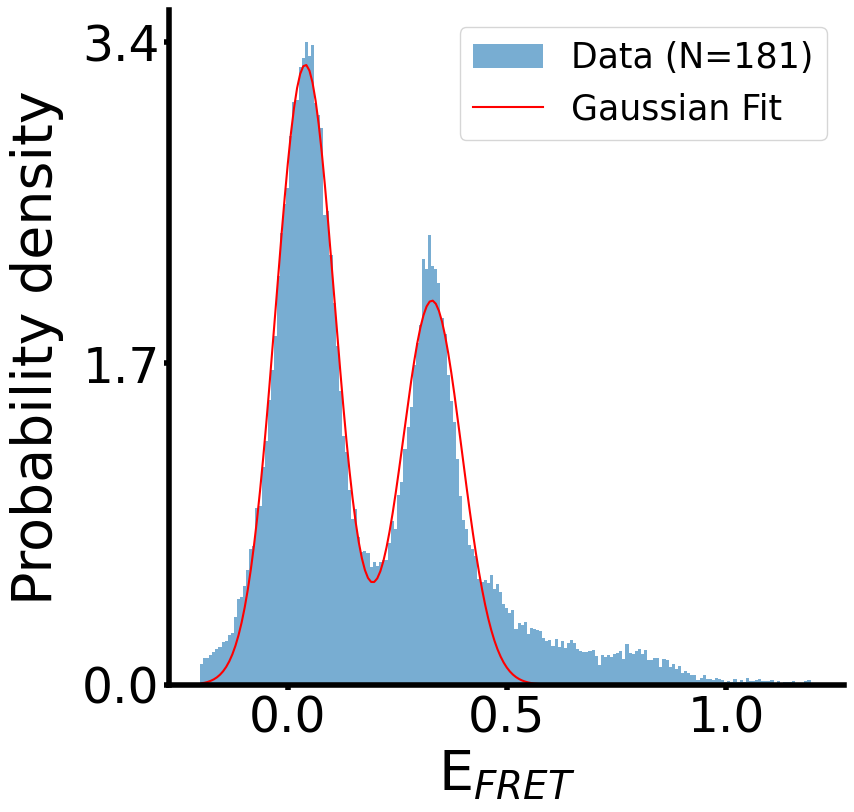

In [7]:
import os
import numpy as np
import csv
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from matplotlib.ticker import FormatStrFormatter

def read_data_from_file(file_path):
    """Read data from .txt file and compute efficiencies for the first 400 data points."""
    data = np.loadtxt(file_path, skiprows=1)
    num_cols = data.shape[1]
    
    # Consider only the first 400 data points
    data = data[:400, :]
    
    efficiencies = []
    for i in range(0, num_cols, 2):  # Process data in pairs of columns
        donor = data[:, i]
        acceptor = data[:, i + 1]
        efficiency = acceptor / (donor + acceptor)
        efficiencies.extend(efficiency)
    
    return efficiencies, num_cols

def save_efficiencies_to_csv(efficiencies, output_file_path):
    """Save the calculated FRET efficiencies to a CSV file."""
    with open(output_file_path, 'w', newline='') as file:
        writer = csv.writer(file)
        for efficiency in efficiencies:
            writer.writerow([efficiency])

def double_gaussian(x, amp1, cen1, sigma1, amp2, cen2, sigma2):
    """Model for a double Gaussian function."""
    return (amp1 * np.exp(-(x - cen1)**2 / (2 * sigma1**2)) +
            amp2 * np.exp(-(x - cen2)**2 / (2 * sigma2**2)))

def plot_histogram(efficiencies, num_observations, tick_count=3, label_fontsize=40, tick_fontsize=35, legend_fontsize=25, tick_decimals=1):
    """Plot histogram of FRET efficiencies and fit with double Gaussian."""
    bins = np.linspace(-0.2, 1.2, 200)
    hist_data, bin_edges = np.histogram(efficiencies, bins=bins, density=True)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
    
    # Fit the double Gaussian to the histogram data
    params, cov = curve_fit(double_gaussian, bin_centers, hist_data, 
                          p0=[max(hist_data)/2, 0, 0.1, max(hist_data)/2, 0.33, 0.1])

    std_errors = np.sqrt(np.diag(cov))
    
    # Calculate areas and their errors
    dx = bin_centers[1] - bin_centers[0]
    area1 = sum(params[0] * np.exp(-(bin_centers - params[1])**2 / (2 * params[2]**2)) * dx)
    area2 = sum(params[3] * np.exp(-(bin_centers - params[4])**2 / (2 * params[5]**2)) * dx)
    
    area1_error = np.sqrt((params[0] * np.sqrt(2*np.pi) * std_errors[2])**2 + (params[2] * np.sqrt(2*np.pi) * std_errors[0])**2)
    area2_error = np.sqrt((params[3] * np.sqrt(2*np.pi) * std_errors[5])**2 + (params[5] * np.sqrt(2*np.pi) * std_errors[3])**2)
    
    print(f"Area under Gaussian 1: {area1:.4f} ± {area1_error:.4f}")
    print(f"Area under Gaussian 2: {area2:.4f} ± {area2_error:.4f}")

    # After calculating areas and their errors
    total_area = area1 + area2
    total_area_error = np.sqrt(area1_error**2 + area2_error**2)

    ratio = area2 / total_area
    ratio_error = ratio * np.sqrt((area2_error/area2)**2 + (total_area_error/total_area)**2)

    print(f"Ratio of Gaussian 2 area over total area: {ratio:.4f} ± {ratio_error:.4f}")

    
    fig, ax = plt.subplots(figsize=(9, 9))  # Creating a square figure

    # Set the linewidth and tick parameters
    for _, spine in ax.spines.items():
        spine.set_linewidth(4.0)
    
    ax.tick_params(width=4.0, labelsize=tick_fontsize)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # Set ticks
    ax.set_xticks(np.linspace(0, 1, tick_count))  # This line ensures that x-ticks go from 0 to 1
    max_density = max(hist_data)
    ax.set_yticks(np.linspace(0, max_density, tick_count))

    # Format ticks to have the specified number of decimals
    ax.xaxis.set_major_formatter(FormatStrFormatter(f'%.{tick_decimals}f'))
    ax.yaxis.set_major_formatter(FormatStrFormatter(f'%.{tick_decimals}f'))
    
    # Plot the histogram and the fit
    ax.hist(efficiencies, bins=bins, density=True, alpha=0.6, edgecolor="none",
             label=f"Data (N={num_observations})")
    ax.plot(bin_centers, double_gaussian(bin_centers, *params), 'r-', label="Gaussian Fit")
    
    
    ax.set_xlabel(r"E$_{FRET}$", fontsize=label_fontsize)
    ax.set_ylabel("Probability density", fontsize=label_fontsize, labelpad=13)
    ax.legend(fontsize=legend_fontsize)
    
    fig.subplots_adjust(left=0.15, right=0.9, top=0.9, bottom=0.15)  # Adjust the subplot spacing to prevent squeezing
    #Save the plot as a .png file
    plt.savefig('notRNA.png', bbox_inches='tight', dpi=300)
    plt.show()

def main(folder_path):
    """Main function to process data from folder and plot histogram."""
    fret_efficiencies = []
    num_observations = 0

    for file_name in os.listdir(folder_path):
        if file_name.endswith('.txt'):
            file_path = os.path.join(folder_path, file_name)
            efficiencies, num_cols = read_data_from_file(file_path)
            fret_efficiencies.extend(efficiencies)
            num_observations += num_cols // 2  # since each observation is represented by a pair of columns

    plot_histogram(fret_efficiencies, num_observations)

    # Save the efficiencies to a CSV file
    output_file_path = os.path.join(folder_path, 'fret_efficiencies.csv')
    save_efficiencies_to_csv(fret_efficiencies, output_file_path)

if __name__ == "__main__":
    folder_path = input("Enter the path of the folder containing the .txt files: ")
    main(folder_path)

Enter the path of the folder containing the .txt files:  /mnt/c/Users/bioed/OneDrive - Northwestern University/Desktop/tmavenMODS/GaussianFRET2/WTtRNA/5uM/


Area under Gaussian 1: 0.5540 ± 0.0100
Area under Gaussian 2: 0.3627 ± 0.0083
Ratio of Gaussian 2 area over total area: 0.3956 ± 0.0106


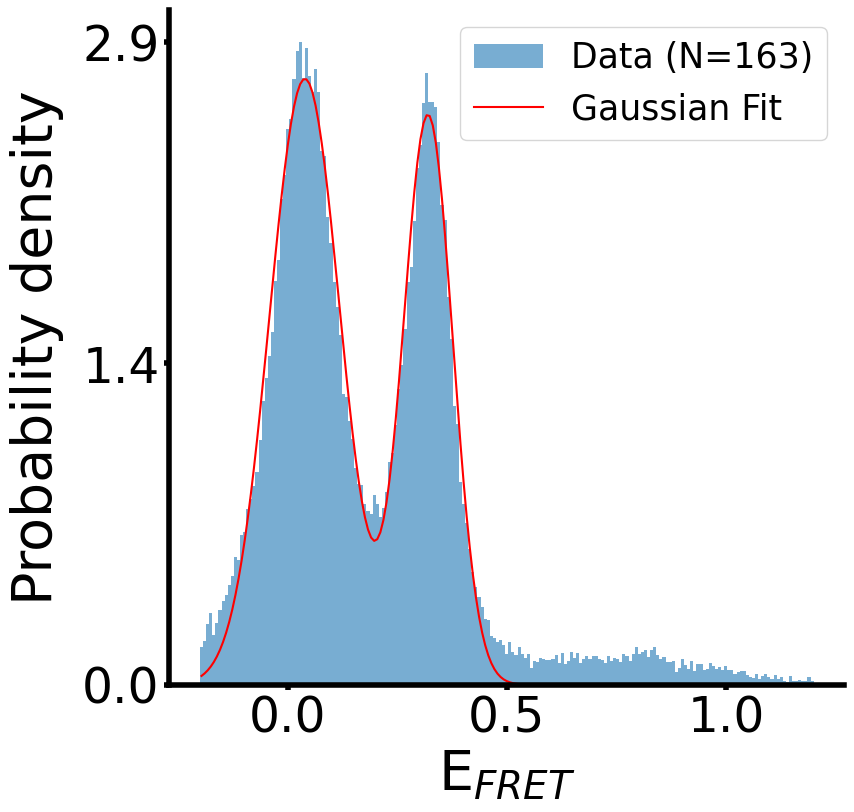

In [8]:
import os
import numpy as np
import csv
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from matplotlib.ticker import FormatStrFormatter

def read_data_from_file(file_path):
    """Read data from .txt file and compute efficiencies for the first 400 data points."""
    data = np.loadtxt(file_path, skiprows=1)
    num_cols = data.shape[1]
    
    # Consider only the first 400 data points
    data = data[:400, :]
    
    efficiencies = []
    for i in range(0, num_cols, 2):  # Process data in pairs of columns
        donor = data[:, i]
        acceptor = data[:, i + 1]
        efficiency = acceptor / (donor + acceptor)
        efficiencies.extend(efficiency)
    
    return efficiencies, num_cols

def save_efficiencies_to_csv(efficiencies, output_file_path):
    """Save the calculated FRET efficiencies to a CSV file."""
    with open(output_file_path, 'w', newline='') as file:
        writer = csv.writer(file)
        for efficiency in efficiencies:
            writer.writerow([efficiency])

def double_gaussian(x, amp1, cen1, sigma1, amp2, cen2, sigma2):
    """Model for a double Gaussian function."""
    return (amp1 * np.exp(-(x - cen1)**2 / (2 * sigma1**2)) +
            amp2 * np.exp(-(x - cen2)**2 / (2 * sigma2**2)))

def plot_histogram(efficiencies, num_observations, tick_count=3, label_fontsize=40, tick_fontsize=35, legend_fontsize=25, tick_decimals=1):
    """Plot histogram of FRET efficiencies and fit with double Gaussian."""
    bins = np.linspace(-0.2, 1.2, 200)
    hist_data, bin_edges = np.histogram(efficiencies, bins=bins, density=True)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
    
    # Fit the double Gaussian to the histogram data
    params, cov = curve_fit(double_gaussian, bin_centers, hist_data, 
                          p0=[max(hist_data)/2, 0, 0.1, max(hist_data)/2, 0.33, 0.1])

    std_errors = np.sqrt(np.diag(cov))
    
    # Calculate areas and their errors
    dx = bin_centers[1] - bin_centers[0]
    area1 = sum(params[0] * np.exp(-(bin_centers - params[1])**2 / (2 * params[2]**2)) * dx)
    area2 = sum(params[3] * np.exp(-(bin_centers - params[4])**2 / (2 * params[5]**2)) * dx)
    
    area1_error = np.sqrt((params[0] * np.sqrt(2*np.pi) * std_errors[2])**2 + (params[2] * np.sqrt(2*np.pi) * std_errors[0])**2)
    area2_error = np.sqrt((params[3] * np.sqrt(2*np.pi) * std_errors[5])**2 + (params[5] * np.sqrt(2*np.pi) * std_errors[3])**2)
    
    print(f"Area under Gaussian 1: {area1:.4f} ± {area1_error:.4f}")
    print(f"Area under Gaussian 2: {area2:.4f} ± {area2_error:.4f}")

    # After calculating areas and their errors
    total_area = area1 + area2
    total_area_error = np.sqrt(area1_error**2 + area2_error**2)

    ratio = area2 / total_area
    ratio_error = ratio * np.sqrt((area2_error/area2)**2 + (total_area_error/total_area)**2)

    print(f"Ratio of Gaussian 2 area over total area: {ratio:.4f} ± {ratio_error:.4f}")

    
    fig, ax = plt.subplots(figsize=(9, 9))  # Creating a square figure

    # Set the linewidth and tick parameters
    for _, spine in ax.spines.items():
        spine.set_linewidth(4.0)
    
    ax.tick_params(width=4.0, labelsize=tick_fontsize)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # Set ticks
    ax.set_xticks(np.linspace(0, 1, tick_count))  # This line ensures that x-ticks go from 0 to 1
    max_density = max(hist_data)
    ax.set_yticks(np.linspace(0, max_density, tick_count))

    # Format ticks to have the specified number of decimals
    ax.xaxis.set_major_formatter(FormatStrFormatter(f'%.{tick_decimals}f'))
    ax.yaxis.set_major_formatter(FormatStrFormatter(f'%.{tick_decimals}f'))
    
    # Plot the histogram and the fit
    ax.hist(efficiencies, bins=bins, density=True, alpha=0.6, edgecolor="none",
             label=f"Data (N={num_observations})")
    ax.plot(bin_centers, double_gaussian(bin_centers, *params), 'r-', label="Gaussian Fit")
    
    
    ax.set_xlabel(r"E$_{FRET}$", fontsize=label_fontsize)
    ax.set_ylabel("Probability density", fontsize=label_fontsize, labelpad=13)
    ax.legend(fontsize=legend_fontsize)
    
    fig.subplots_adjust(left=0.15, right=0.9, top=0.9, bottom=0.15)  # Adjust the subplot spacing to prevent squeezing
    #Save the plot as a .png file
    plt.savefig('notRNA.png', bbox_inches='tight', dpi=300)
    plt.show()

def main(folder_path):
    """Main function to process data from folder and plot histogram."""
    fret_efficiencies = []
    num_observations = 0

    for file_name in os.listdir(folder_path):
        if file_name.endswith('.txt'):
            file_path = os.path.join(folder_path, file_name)
            efficiencies, num_cols = read_data_from_file(file_path)
            fret_efficiencies.extend(efficiencies)
            num_observations += num_cols // 2  # since each observation is represented by a pair of columns

    plot_histogram(fret_efficiencies, num_observations)

    # Save the efficiencies to a CSV file
    output_file_path = os.path.join(folder_path, 'fret_efficiencies.csv')
    save_efficiencies_to_csv(fret_efficiencies, output_file_path)

if __name__ == "__main__":
    folder_path = input("Enter the path of the folder containing the .txt files: ")
    main(folder_path)

Enter the path of the folder containing the .txt files:  /mnt/c/Users/bioed/OneDrive - Northwestern University/Desktop/tmavenMODS/GaussianFRET2/WTtRNA/13uM/


Area under Gaussian 1: 0.5294 ± 0.0139
Area under Gaussian 2: 0.3781 ± 0.0111
Ratio of Gaussian 2 area over total area: 0.4166 ± 0.0147


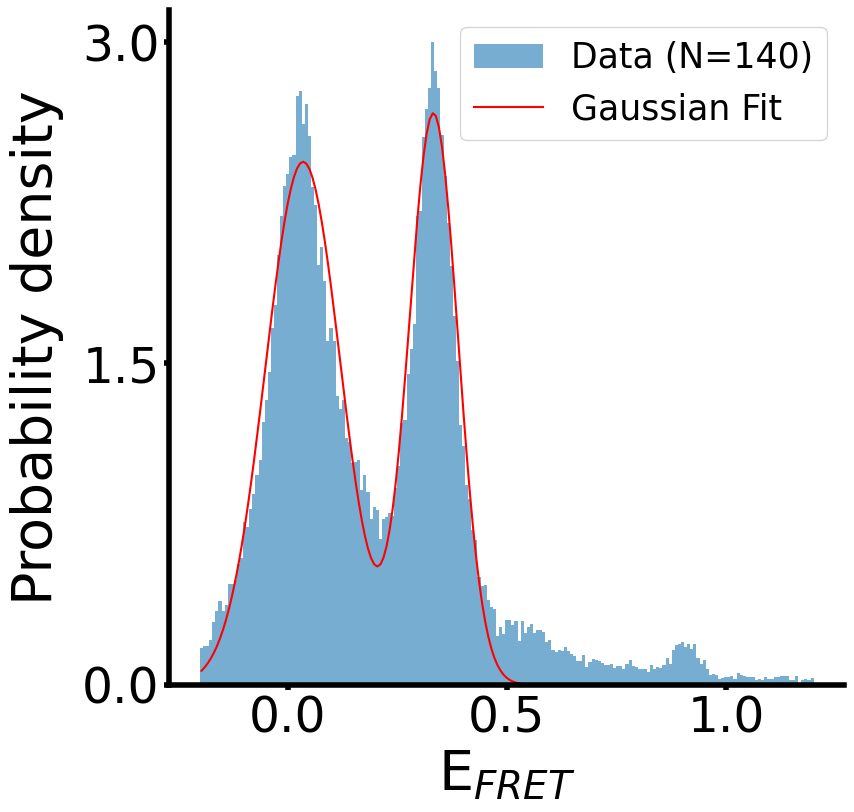

In [9]:
import os
import numpy as np
import csv
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from matplotlib.ticker import FormatStrFormatter

def read_data_from_file(file_path):
    """Read data from .txt file and compute efficiencies for the first 400 data points."""
    data = np.loadtxt(file_path, skiprows=1)
    num_cols = data.shape[1]
    
    # Consider only the first 400 data points
    data = data[:400, :]
    
    efficiencies = []
    for i in range(0, num_cols, 2):  # Process data in pairs of columns
        donor = data[:, i]
        acceptor = data[:, i + 1]
        efficiency = acceptor / (donor + acceptor)
        efficiencies.extend(efficiency)
    
    return efficiencies, num_cols

def save_efficiencies_to_csv(efficiencies, output_file_path):
    """Save the calculated FRET efficiencies to a CSV file."""
    with open(output_file_path, 'w', newline='') as file:
        writer = csv.writer(file)
        for efficiency in efficiencies:
            writer.writerow([efficiency])

def double_gaussian(x, amp1, cen1, sigma1, amp2, cen2, sigma2):
    """Model for a double Gaussian function."""
    return (amp1 * np.exp(-(x - cen1)**2 / (2 * sigma1**2)) +
            amp2 * np.exp(-(x - cen2)**2 / (2 * sigma2**2)))

def plot_histogram(efficiencies, num_observations, tick_count=3, label_fontsize=40, tick_fontsize=35, legend_fontsize=25, tick_decimals=1):
    """Plot histogram of FRET efficiencies and fit with double Gaussian."""
    bins = np.linspace(-0.2, 1.2, 200)
    hist_data, bin_edges = np.histogram(efficiencies, bins=bins, density=True)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
    
    # Fit the double Gaussian to the histogram data
    params, cov = curve_fit(double_gaussian, bin_centers, hist_data, 
                          p0=[max(hist_data)/2, 0, 0.1, max(hist_data)/2, 0.33, 0.1])

    std_errors = np.sqrt(np.diag(cov))
    
    # Calculate areas and their errors
    dx = bin_centers[1] - bin_centers[0]
    area1 = sum(params[0] * np.exp(-(bin_centers - params[1])**2 / (2 * params[2]**2)) * dx)
    area2 = sum(params[3] * np.exp(-(bin_centers - params[4])**2 / (2 * params[5]**2)) * dx)
    
    area1_error = np.sqrt((params[0] * np.sqrt(2*np.pi) * std_errors[2])**2 + (params[2] * np.sqrt(2*np.pi) * std_errors[0])**2)
    area2_error = np.sqrt((params[3] * np.sqrt(2*np.pi) * std_errors[5])**2 + (params[5] * np.sqrt(2*np.pi) * std_errors[3])**2)
    
    print(f"Area under Gaussian 1: {area1:.4f} ± {area1_error:.4f}")
    print(f"Area under Gaussian 2: {area2:.4f} ± {area2_error:.4f}")

    # After calculating areas and their errors
    total_area = area1 + area2
    total_area_error = np.sqrt(area1_error**2 + area2_error**2)

    ratio = area2 / total_area
    ratio_error = ratio * np.sqrt((area2_error/area2)**2 + (total_area_error/total_area)**2)

    print(f"Ratio of Gaussian 2 area over total area: {ratio:.4f} ± {ratio_error:.4f}")

    
    fig, ax = plt.subplots(figsize=(9, 9))  # Creating a square figure

    # Set the linewidth and tick parameters
    for _, spine in ax.spines.items():
        spine.set_linewidth(4.0)
    
    ax.tick_params(width=4.0, labelsize=tick_fontsize)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # Set ticks
    ax.set_xticks(np.linspace(0, 1, tick_count))  # This line ensures that x-ticks go from 0 to 1
    max_density = max(hist_data)
    ax.set_yticks(np.linspace(0, max_density, tick_count))

    # Format ticks to have the specified number of decimals
    ax.xaxis.set_major_formatter(FormatStrFormatter(f'%.{tick_decimals}f'))
    ax.yaxis.set_major_formatter(FormatStrFormatter(f'%.{tick_decimals}f'))
    
    # Plot the histogram and the fit
    ax.hist(efficiencies, bins=bins, density=True, alpha=0.6, edgecolor="none",
             label=f"Data (N={num_observations})")
    ax.plot(bin_centers, double_gaussian(bin_centers, *params), 'r-', label="Gaussian Fit")
    
    
    ax.set_xlabel(r"E$_{FRET}$", fontsize=label_fontsize)
    ax.set_ylabel("Probability density", fontsize=label_fontsize, labelpad=13)
    ax.legend(fontsize=legend_fontsize)
    
    fig.subplots_adjust(left=0.15, right=0.9, top=0.9, bottom=0.15)  # Adjust the subplot spacing to prevent squeezing
    #Save the plot as a .png file
    plt.savefig('notRNA.png', bbox_inches='tight', dpi=300)
    plt.show()

def main(folder_path):
    """Main function to process data from folder and plot histogram."""
    fret_efficiencies = []
    num_observations = 0

    for file_name in os.listdir(folder_path):
        if file_name.endswith('.txt'):
            file_path = os.path.join(folder_path, file_name)
            efficiencies, num_cols = read_data_from_file(file_path)
            fret_efficiencies.extend(efficiencies)
            num_observations += num_cols // 2  # since each observation is represented by a pair of columns

    plot_histogram(fret_efficiencies, num_observations)

    # Save the efficiencies to a CSV file
    output_file_path = os.path.join(folder_path, 'fret_efficiencies.csv')
    save_efficiencies_to_csv(fret_efficiencies, output_file_path)

if __name__ == "__main__":
    folder_path = input("Enter the path of the folder containing the .txt files: ")
    main(folder_path)

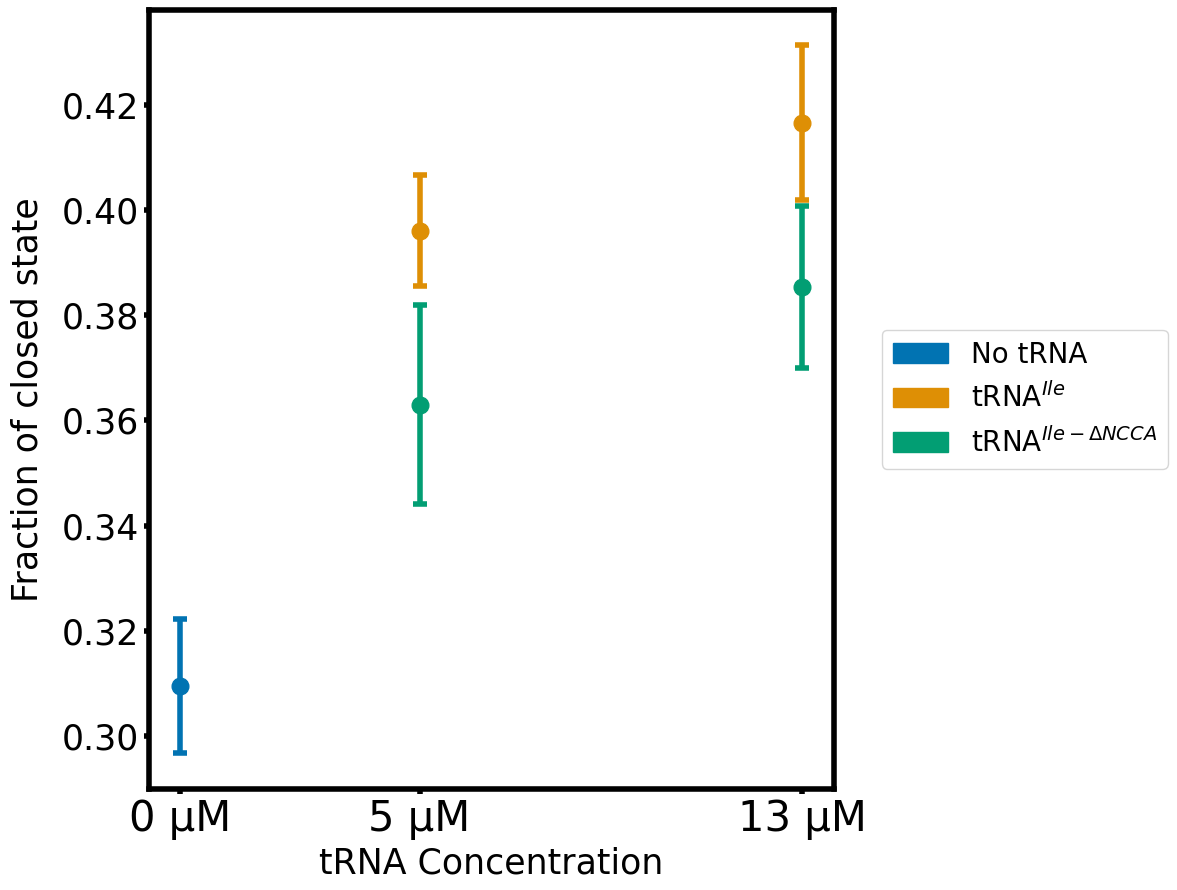

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import matplotlib.patches as mpatches

# Sample data
data = {
    'Factor1': ["No tRNA", r"tRNA$^{Ile}$", r"tRNA$^{Ile}$", r"tRNA$^{Ile-ΔNCCA}$", r"tRNA$^{Ile-ΔNCCA}$"],
    'Factor2': ["0 µM", "5 µM", "13 µM", "5 µM", "13 µM"],
    'Value': [0.3095, 0.3961, 0.4166, 0.3630, 0.3853],
    'Error': [0.0128, 0.0106, 0.0147, 0.0189, 0.0154]
}
df = pd.DataFrame(data)

# Convert Factor2 to a numerical value for plotting
tRNA_concentration_map = {"0 µM": 0, "5 µM": 5, "13 µM": 13}
df['tRNA_concentration'] = df['Factor2'].map(tRNA_concentration_map)

# Set a color palette
colors = sns.color_palette("colorblind", n_colors=len(df['Factor1'].unique()))

# Set up the plotting environment with specified figsize
fig, ax = plt.subplots(figsize=(12, 9))

# Adjust the line width of the spines and tick lines
for spine in ax.spines.values():
    spine.set_linewidth(4.0)
ax.tick_params(width=4.0, labelsize=25)

# Dictionary to map Factor1 levels to colors
color_map = {factor: colors[i] for i, factor in enumerate(df['Factor1'].unique())}

# Create legend entries
legend_handles = [mpatches.Patch(color=color_map[factor], label=factor) for factor in df['Factor1'].unique()]

# Plotting scatter with error bars
for idx, row in df.iterrows():
    ax.errorbar(x=row['tRNA_concentration'], y=row['Value'], yerr=row['Error'], fmt='o', 
                color=color_map[row['Factor1']], capsize=5, elinewidth=4, capthick=4, markersize=12, 
                label=row['Factor1'] if row['Factor1'] not in [h.get_label() for h in legend_handles] else "")

# Set x-axis labels and legend
ax.set_xticks(list(tRNA_concentration_map.values()))
ax.set_xticklabels(list(tRNA_concentration_map.keys()), fontsize=30)
legend = ax.legend(handles=legend_handles, fontsize=20, loc='center left', bbox_to_anchor=(1.05, 0.5))
legend.get_title().set_fontsize('20')

ax.set_xlabel("tRNA Concentration", fontsize=25)
ax.set_ylabel("Fraction of closed state", labelpad=13, fontsize=25)

plt.tight_layout()

# Save the plot as a .png file
plt.savefig('scatterplot.png', bbox_inches='tight', dpi=300)

plt.show()